[Text(0, 0.5, 'Total generation (MW)'),
 Text(0.5, 1.0, 'GB generation every 5 minutes, Euro 2024 semi-final')]

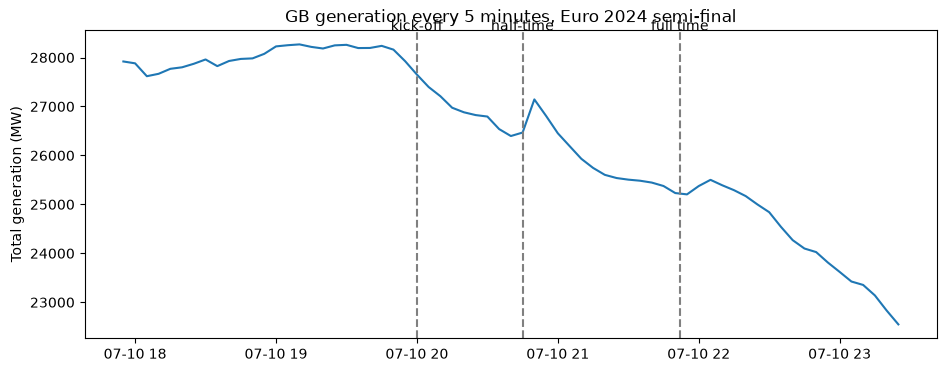

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from gridforecast.config import UK
from gridforecast.data.elexon import fetch_fuelinst

# Euro 2024 semi-final, England v Netherlands, kick-off 20:00 UK time
gen = fetch_fuelinst("2024-07-10T17:00Z", "2024-07-10T22:30Z")
local = gen["start_time"].dt.tz_convert(UK)
kickoff = pd.Timestamp("2024-07-10 20:00", tz=UK)

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(local, gen["generation_mw"])
for minutes, label in ((0, "kick-off"), (45, "half-time"), (112, "full time")):
    ax.axvline(kickoff + pd.Timedelta(minutes=minutes), color="grey", ls="--")
    ax.text(kickoff + pd.Timedelta(minutes=minutes), ax.get_ylim()[1], label, ha="center")
ax.set(ylabel="Total generation (MW)", title="GB generation every 5 minutes, Euro 2024 semi-final")